In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def fred(series_id):
    url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
    df = pd.read_csv(url)
    df.columns = ["date", series_id]
    df["date"] = pd.to_datetime(df["date"])
    df[series_id] = pd.to_numeric(df[series_id], errors="coerce")
    return df.set_index("date")

cpi = fred("CPIAUCSL")
mich = fred("MICH")
print(cpi.tail(3))
print(mich.tail(3))


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.11/site-p

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.11/site-packages/traitlets/config/application.py", line 992, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.11/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.11/site-p

AttributeError: _ARRAY_API not found

            CPIAUCSL
date                
2026-07-01   332.813
2026-08-01   334.131
2026-09-01   336.298
            MICH
date            
2026-07-01   4.2
2026-08-01   4.0
2026-09-01   4.6


In [2]:
cpi["cpi_yoy"] = cpi["CPIAUCSL"].pct_change(12) * 100

df = cpi[["cpi_yoy"]].join(mich.rename(columns={"MICH": "mich_expect"}), how="inner")
df = df.loc["2021-01-01":].dropna()
print(df.shape)
df.head()

(68, 2)


,cpi_yoy,mich_expect
date,,
2021-01-01,1.373844,3.0
2021-02-01,1.669817,3.3
2021-03-01,2.667819,3.1
2021-04-01,4.133077,3.4
2021-05-01,4.918257,4.6


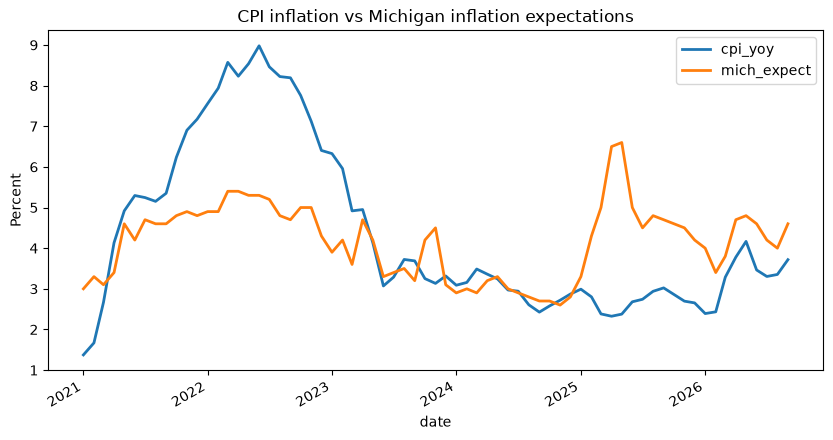

In [3]:
ax = df.plot(figsize=(10, 5), lw=2)
ax.set_title("CPI inflation vs Michigan inflation expectations")
ax.set_ylabel("Percent")
plt.show()

In [4]:
df.to_csv("../data/official.csv")
print("saved")

saved


In [5]:
from datasets import load_dataset
ds = load_dataset("sidewayzaits/reddit_about_money", split="train")
d = ds.to_pandas()   
print(d.columns.tolist())
print(len(d))
print(d.head(3))

['Title', 'Score', 'URL', 'Comments', "It's crazy that I almost thought about monetizing this, rather than giving it for free. It's time to realize and the real flaw of money--it makes people selfish. I want to end that and make people care about each other again. Here is my year long TradingView project, for free. I keep the code tho :)", '601', 'https://www.reddit.com/r/Trading/comments/lxd6d5/its_crazy_that_i_almost_thought_about_monetizing/', 'Throw some ads on the page and we\'ll be happy to click them for you!!\nI haven’t really checked out the indi yet, but man I like your style.  \n\nI can help with your website, maybe convert to TOS, idk other stuff too probably.  Feel free to pm  if you need anything.  You rock.\n[deleted]\nOMG I love to know that people like you, unselfish and caring for the little people are here and willing to help others with nothing in return than the satisfaction of helping. Thank you so much!👌🙏🙏\nI used this today and had great success with entering tr

In [8]:
col = "Date"  # Replace with the actual column name from d.columns.tolist()
d["date"] = pd.to_datetime(d[col], unit="s", errors="coerce")
print(d["date"].min(), d["date"].max())
print(d.groupby(d["date"].dt.to_period("M")).size())

NaT NaT
Series([], Freq: M, dtype: int64)


In [10]:
KEYWORDS = ["inflation","prices","grocery","groceries","rent","gas prices",
            "cost of living","expensive","afford","mortgage rates","price hike"]
pat = "|".join(KEYWORDS)
text_col = "text"   # change to the real text column name
t = d[d[text_col].str.contains(pat, case=False, na=False)].copy()
t["month"] = t["date"].dt.to_period("M")
print(t.groupby("month").size())
t[["date", text_col]].rename(columns={text_col: "text"}).to_parquet("../data/text_raw.parquet")

KeyError: 'text'

In [12]:
pip install pytrends

Note: you may need to restart the kernel to use updated packages.


<Axes: xlabel='date'>

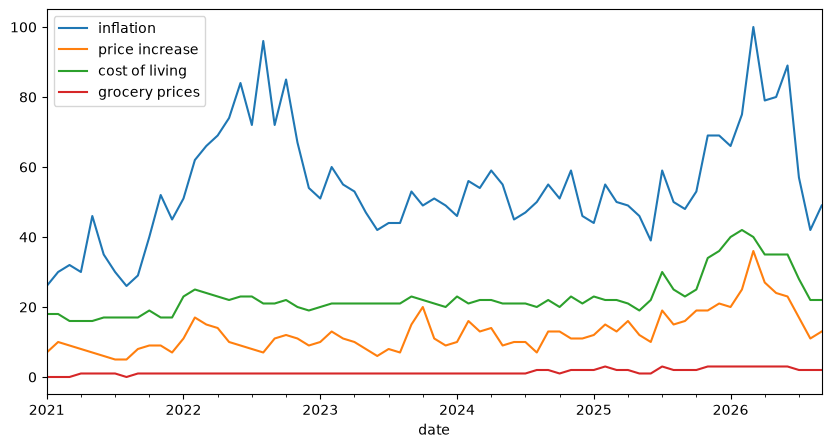

In [14]:
from pytrends.request import TrendReq
pt = TrendReq(hl="en-US", tz=360)
terms = ["inflation", "price increase", "cost of living", "grocery prices"]
pt.build_payload(terms, timeframe="2021-01-01 2026-09-30", geo="US")
trends = pt.interest_over_time().drop(columns="isPartial")
trends.to_csv("../data/trends.csv")
trends.plot(figsize=(10, 5))

<Axes: title={'center': 'Price attention index (z-score)'}, xlabel='date'>

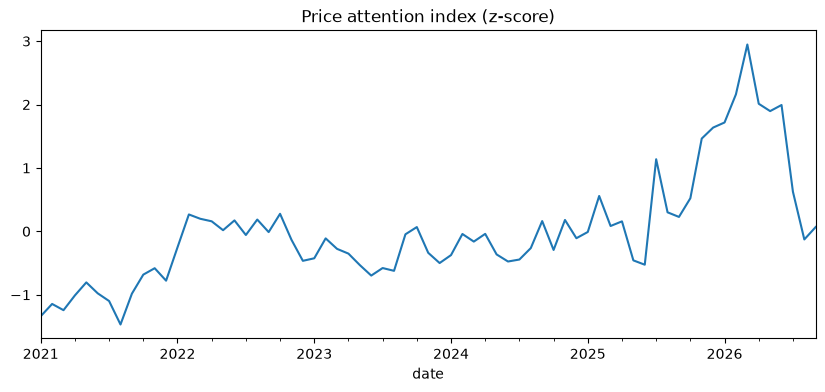

In [16]:
t = trends.copy()
t.index = pd.to_datetime(t.index)
t = t.resample("MS").mean()          # one row per month

z = (t - t.mean()) / t.std()          # z-score each term separately
t["attention"] = z.mean(axis=1)       # average into one index
t["attention"].plot(figsize=(10, 4), title="Price attention index (z-score)")

In [18]:
off = pd.read_csv("../data/official.csv", index_col=0, parse_dates=True)
d = t[["attention"]].join(off, how="inner").dropna()
print(d.shape)
d.head()

(68, 3)


,attention,cpi_yoy,mich_expect
date,,,
2021-01-01,-1.338393,1.373844,3.0
2021-02-01,-1.144756,1.669817,3.3
2021-03-01,-1.242915,2.667819,3.1
2021-04-01,-1.009863,4.133077,3.4
2021-05-01,-0.804897,4.918257,4.6
